# 🌌 Galaxy Collision Simulator
### A restricted N-body simulation of two Milky-Way-like spiral galaxies colliding and merging

**How to run:** `Runtime → Run all`. In about 3 minutes the notebook simulates ~1 billion years, renders a video, and **automatically downloads** two files:
- 🎥 `galaxy_collision.mp4`: the collision movie
- 📊 `galaxy_collision_science.png`: rotation curve, orbital decay and snapshots

*(If your browser asks, click **Allow** for multiple downloads.)*

---
**The science.** When galaxies collide, their stars almost never hit each other because the gaps between them are enormous. Instead, **gravity** distorts both galaxies. Tidal forces pull out long **tidal tails** and a **bridge** of stars. Then **dynamical friction** (the drag a galaxy feels as it ploughs through the other's dark-matter halo) steals orbital energy, so the two galaxies fall back together and **merge** into one. The Milky Way and Andromeda will do this in about 4–5 billion years.

**The model.**
| Ingredient | What we use |
|---|---|
| Method | Restricted N-body (Toomre & Toomre 1972): stars are test particles moving in the gravity of both galaxies |
| Galaxy potential | Plummer bulge (4×10¹⁰ M☉) + Hernquist dark-matter halo (6×10¹¹ M☉), which gives a flat ~210 km/s rotation curve |
| Stellar disk | Exponential disk (scale length 3 kpc) with 2 logarithmic spiral arms + a spherical bulge |
| Orbit | Parabolic encounter (E = 0), prograde for galaxy 1, galaxy 2 inclined by 60° |
| Merging | Chandrasekhar dynamical friction, ln Λ = ln 2 |
| Integrator | Kick-Drift-Kick leapfrog (symplectic, 2nd order), Δt ≈ 0.24 Myr |
| Units | G = 1, 1 kpc, 10¹⁰ M☉ → 207 km/s, 4.7 Myr |

Star colours follow stellar populations: old, cool **yellow-red** stars in the bulge, young, hot **blue** stars along the spiral arms, and **pink** H II star-forming regions.

## 1 · Settings
Change `FAST_MODE = False` for a denser, 1080p render (slower).

In [1]:
# 1. SETTINGS
import numpy as np
from scipy.ndimage import gaussian_filter, zoom
from scipy.special import erf
from PIL import Image, ImageDraw, ImageFont
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import subprocess, shutil, os, time
from IPython.display import Video, Image as IPImage, display

# ---- Output ----
OUTPUT_VIDEO = "galaxy_collision.mp4"
OUTPUT_PLOT  = "galaxy_collision_science.png"
AUTO_DOWNLOAD = True        # download the video + science plot automatically at the end

# ---- Quality ----
# True  : ~2-4 min on free Colab, 10,000 stars
# False : ~6-10 min, 24,000 stars, 1080p, smoother
FAST_MODE = True
if FAST_MODE:
    N_STARS_PER_GALAXY = 5000
    SIZE = 720
    SAVE_EVERY = 8          # simulation steps per video frame
else:
    N_STARS_PER_GALAXY = 12000
    SIZE = 1080
    SAVE_EVERY = 6
FPS = 30
np.random.seed(7)

# ---- Units ----
# G = 1, [length] = 1 kpc, [mass] = 1e10 solar masses
# => [velocity] = 207.4 km/s, [time] = 4.715 Myr
KPC_PER_UNIT  = 1.0
KMS_PER_UNIT  = 207.4
MYR_PER_UNIT  = 4.715
G = 1.0

# ---- Galaxy model (each galaxy is Milky-Way-like) ----
M_BULGE, A_BULGE = 4.0, 1.0     # Plummer bulge: 4e10 Msun, scale 1 kpc
M_HALO,  A_HALO  = 60.0, 20.0   # Hernquist dark-matter halo: 6e11 Msun, scale 20 kpc
M_GAL = M_BULGE + M_HALO
R_DISK  = 3.0                   # exponential disk scale length [kpc]
R_MAX   = 18.0                  # disk truncation radius [kpc]
Z_DISK  = 0.3                   # disk scale height [kpc]
SIGMA_V = 0.05                  # disk velocity dispersion (~10 km/s)
BULGE_FRAC = 0.15               # fraction of tracer stars in the bulge
N_ARMS, ARM_PITCH = 2, 0.38     # logarithmic spiral arms
SOFT = 0.3                      # gravitational softening [kpc]

# ---- Encounter (Toomre & Toomre style parabolic orbit) ----
R_START   = 80.0                # initial separation [kpc]
R_PERI    = 10.0                # Keplerian pericentre distance [kpc]
INC_1, PA_1 = np.radians(15), np.radians(0)    # galaxy 1: nearly face-on, prograde
INC_2, PA_2 = np.radians(60), np.radians(70)   # galaxy 2: strongly inclined
COULOMB_LOG = np.log(2.0)       # ln(Lambda) = ln(1 + M_host/M_sat) for equal masses

# ---- Integration ----
DT      = 0.05                  # ~0.24 Myr
T_END   = 205.0                 # ~970 Myr
N_STEPS = int(T_END / DT)

# ---- Camera ----
VIEW_START, VIEW_END = 62.0, 38.0   # half-width of the field of view [kpc]

print(f"Stars: {2*N_STARS_PER_GALAXY:,}  |  steps: {N_STEPS:,}  |  "
      f"simulated time: {T_END*MYR_PER_UNIT:.0f} Myr")


Stars: 10,000  |  steps: 4,100  |  simulated time: 967 Myr


## 2 · Physics
Each galaxy's gravity comes from the mass enclosed within radius *r*: $\;a(r) = -G\,M(<r)/r^2$, with
$$M(<r) = M_b\frac{r^3}{(r^2+a_b^2)^{3/2}} + M_h\frac{r^2}{(r+a_h)^2}$$
Dynamical friction (Chandrasekhar 1943):
$$\mathbf{a}_{df} = -\frac{4\pi G^2 M \rho(r) \ln\Lambda}{v^3}\left[\mathrm{erf}(X) - \frac{2X}{\sqrt{\pi}}e^{-X^2}\right]\mathbf{v},\qquad X = \frac{v}{\sqrt{2}\,\sigma}$$

In [2]:
# 2. PHYSICS: potential, rotation curve, dynamical friction
def m_enclosed(r):
    """Mass inside radius r: Plummer bulge + Hernquist dark halo."""
    return (M_BULGE * r**3 / (r**2 + A_BULGE**2)**1.5
            + M_HALO * r**2 / (r + A_HALO)**2)

def v_circ(r):
    return np.sqrt(G * m_enclosed(r) / r)

def halo_density(r):
    r = np.maximum(r, 0.3)
    return M_HALO * A_HALO / (2 * np.pi * r * (r + A_HALO)**3)

def accel_from(core, pos):
    """Gravitational acceleration at `pos` due to one galaxy centred at `core`."""
    d = core - pos
    r = np.sqrt(np.sum(d * d, axis=-1) + SOFT**2)
    return (G * m_enclosed(r) / r**3)[..., None] * d

def dynamical_friction(v_rel, r):
    """Chandrasekhar dynamical friction on a galaxy moving through the other's halo."""
    v = np.linalg.norm(v_rel) + 1e-9
    sigma = v_circ(max(r, 0.3)) / np.sqrt(2)          # isothermal approximation
    X = v / (np.sqrt(2) * sigma)
    f = erf(X) - 2 * X / np.sqrt(np.pi) * np.exp(-X * X)
    return -4 * np.pi * G**2 * M_GAL * halo_density(r) * COULOMB_LOG * f / v**3 * v_rel


## 3 · Initial conditions
Stars start on circular orbits with $v_c = \sqrt{G M(<r)/r}$ taken from the *same* potential, so each disk is in equilibrium before the encounter. The galaxies start 80 kpc apart on a parabolic orbit.

In [3]:
# 3. INITIAL CONDITIONS
def rotation_matrix(inc, pa):
    ci, si, cp, sp = np.cos(inc), np.sin(inc), np.cos(pa), np.sin(pa)
    Rx = np.array([[1, 0, 0], [0, ci, -si], [0, si, ci]])
    Rz = np.array([[cp, -sp, 0], [sp, cp, 0], [0, 0, 1]])
    return Rz @ Rx

def make_galaxy(N, inc, pa):
    nb = int(N * BULGE_FRAC); nd = N - nb

    # --- Disk: exponential surface density + logarithmic spiral arms ---
    r = np.random.gamma(2.0, R_DISK, nd)               # Sigma ~ exp(-r/Rd) => p(r) ~ r exp(-r/Rd)
    r = np.clip(r, 0.6, R_MAX)
    arm = np.random.randint(0, N_ARMS, nd) * 2 * np.pi / N_ARMS
    on_arm = np.random.random(nd) < 0.65
    theta = np.where(on_arm,
                     np.log(r) / np.tan(ARM_PITCH) + arm + np.random.normal(0, 0.28, nd),
                     np.random.uniform(0, 2 * np.pi, nd))
    xd = np.column_stack([r * np.cos(theta), r * np.sin(theta),
                          np.random.laplace(0, Z_DISK, nd)])
    vc = v_circ(r)
    vd = np.column_stack([-vc * np.sin(theta), vc * np.cos(theta), np.zeros(nd)])
    vd += np.random.normal(0, SIGMA_V, vd.shape)

    # --- Bulge: Plummer sphere, stars on randomly oriented circular orbits ---
    u = np.random.uniform(0.02, 0.9, nb)
    rb = A_BULGE / np.sqrt(u**(-2/3) - 1)
    nhat = np.random.normal(size=(nb, 3)); nhat /= np.linalg.norm(nhat, axis=1)[:, None]
    xb = rb[:, None] * nhat
    t = np.cross(nhat, np.random.normal(size=(nb, 3))); t /= np.linalg.norm(t, axis=1)[:, None]
    vb = v_circ(rb)[:, None] * t

    pos = np.vstack([xd, xb]); vel = np.vstack([vd, vb])
    R = rotation_matrix(inc, pa)
    pos, vel = pos @ R.T, vel @ R.T

    # --- Stellar populations (colour ~ temperature, brightness ~ luminosity) ---
    # disk arms: young, hot, blue-white stars;  inter-arm: mixed;  bulge: old, cool, yellow-red
    temp = np.concatenate([
        np.where(on_arm, np.random.normal(0.78, 0.15, nd), np.random.normal(0.50, 0.15, nd)),
        np.random.normal(0.22, 0.10, nb)])
    lum = np.concatenate([
        np.exp(-r / (2.5 * R_DISK)) * np.random.lognormal(0, 0.75, nd),
        1.5 * np.random.lognormal(0, 0.5, nb)])
    pop = np.concatenate([np.where(on_arm, 1, 2), np.zeros(nb, int)])  # 0 bulge, 1 arm, 2 inter-arm

    # a few luminous O/B stars and pink H-II (star-forming) regions along the arms
    arm_idx = np.where(pop == 1)[0]
    ob = np.random.choice(arm_idx, int(0.012 * N), replace=False)
    lum[ob] *= np.random.uniform(8, 20, ob.size); temp[ob] = 1.0
    hii = np.random.choice(arm_idx, int(0.02 * N), replace=False)
    pop[hii] = 3; lum[hii] *= 2.5
    return pos, vel, np.clip(temp, 0, 1), lum, pop


def star_colour(temp, pop):
    """Approximate blackbody colours: cool red-orange -> yellow -> white -> hot blue."""
    t_pts = [0.0, 0.35, 0.6, 1.0]
    rgb = np.column_stack([np.interp(temp, t_pts, [1.00, 1.00, 1.00, 0.62]),
                           np.interp(temp, t_pts, [0.52, 0.80, 0.95, 0.76]),
                           np.interp(temp, t_pts, [0.28, 0.52, 0.88, 1.00])])
    rgb[pop == 3] = [1.0, 0.36, 0.60]                 # H-alpha pink star-forming regions
    return rgb


# Parabolic two-body orbit: E = 0, L = sqrt(2 G M_tot r_p)
Mtot = 2 * M_GAL
v_par = np.sqrt(2 * G * Mtot / R_START)
v_t = np.sqrt(2 * G * Mtot * R_PERI) / R_START
v_r = -np.sqrt(v_par**2 - v_t**2)
rel_x = np.array([R_START, 0.0, 0.0]); rel_v = np.array([v_r, v_t, 0.0])
ang = np.radians(-25)                                  # rotate so the approach looks diagonal
Rot = np.array([[np.cos(ang), -np.sin(ang), 0], [np.sin(ang), np.cos(ang), 0], [0, 0, 1]])
rel_x, rel_v = Rot @ rel_x, Rot @ rel_v

c1, c2 = -rel_x / 2, rel_x / 2
v1, v2 = -rel_v / 2, rel_v / 2

p1, w1, T1, L1, P1 = make_galaxy(N_STARS_PER_GALAXY, INC_1, PA_1)
p2, w2, T2, L2, P2 = make_galaxy(N_STARS_PER_GALAXY, INC_2, PA_2)
pos = np.vstack([p1 + c1, p2 + c2]).astype(np.float64)
vel = np.vstack([w1 + v1, w2 + v2]).astype(np.float64)
lum = np.concatenate([L1, L2]); colour = star_colour(np.concatenate([T1, T2]),
                                                     np.concatenate([P1, P2]))
origin = np.repeat([0, 1], N_STARS_PER_GALAXY)


## 4 · N-body integration
Kick-Drift-Kick leapfrog: a time-reversible, symplectic scheme that conserves energy well over long orbital integrations.

In [4]:
# 4. N-BODY INTEGRATION (Kick-Drift-Kick leapfrog)
def core_accels(c1, c2, v1, v2):
    d = c2 - c1
    r = np.linalg.norm(d)
    g12 = accel_from(c2, c1[None])[0]
    return (g12 + dynamical_friction(v1 - v2, r),
            -g12 + dynamical_friction(v2 - v1, r))

def star_accels(pos, c1, c2):
    return accel_from(c1, pos) + accel_from(c2, pos)

frames_pos, frames_c, times, seps = [], [], [], []
a_s = star_accels(pos, c1, c2); a1, a2 = core_accels(c1, c2, v1, v2)
t0 = time.time()
print("Integrating orbits ...")
for step in range(N_STEPS + 1):
    if step % SAVE_EVERY == 0:
        frames_pos.append(pos.astype(np.float32).copy())
        frames_c.append(np.array([c1, c2]))
        times.append(step * DT * MYR_PER_UNIT)
        seps.append(np.linalg.norm(c2 - c1))
    # kick (half) - drift - kick (half)
    vel += 0.5 * DT * a_s; v1 += 0.5 * DT * a1; v2 += 0.5 * DT * a2
    pos += DT * vel;       c1 += DT * v1;       c2 += DT * v2
    a_s = star_accels(pos, c1, c2); a1, a2 = core_accels(c1, c2, v1, v2)
    vel += 0.5 * DT * a_s; v1 += 0.5 * DT * a1; v2 += 0.5 * DT * a2
    if step % 1000 == 0:
        print(f"  t = {step*DT*MYR_PER_UNIT:6.0f} Myr   separation = {seps[-1]:5.1f} kpc")

times, seps = np.array(times), np.array(seps)
N_FRAMES = len(frames_pos)
print(f"Done in {time.time()-t0:.1f} s  ->  {N_FRAMES} frames")

# Identify the dynamical phases from the separation curve
mins = [i for i in range(1, N_FRAMES - 1) if seps[i] < seps[i-1] and seps[i] <= seps[i+1] and seps[i] > 2]
maxs = [i for i in range(1, N_FRAMES - 1) if seps[i] > seps[i-1] and seps[i] >= seps[i+1]]
peri1 = mins[0] if mins else N_FRAMES // 3
apo   = next((m for m in maxs if m > peri1), (peri1 + N_FRAMES) // 2)
merge = next((i for i in range(apo, N_FRAMES) if seps[i] < 3.0), N_FRAMES - 1)

def phase(i):
    if i < peri1 - 12:   return "Approach"
    if i < peri1 + 12:   return "First pericentre passage"
    if i <= apo:         return "Tidal tails & bridge form"
    if i < merge - 15:   return "Fall-back (dynamical friction)"
    if i < merge + 10:   return "Final coalescence"
    return "Merger remnant"

print(f"First pericentre: {times[peri1]:.0f} Myr at {seps[peri1]:.1f} kpc | "
      f"apocentre: {times[apo]:.0f} Myr at {seps[apo]:.1f} kpc | merger: ~{times[merge]:.0f} Myr")


Integrating orbits ...
  t =      0 Myr   separation =  80.0 kpc
  t =    236 Myr   separation =  25.4 kpc
  t =    472 Myr   separation =  45.4 kpc
  t =    707 Myr   separation =   6.2 kpc
  t =    943 Myr   separation =   0.5 kpc
Done in 14.0 s  ->  513 frames
First pericentre: 187 Myr at 17.5 kpc | apocentre: 417 Myr at 47.0 kpc | merger: ~751 Myr


## 5 · Rendering
Stars are deposited with sub-pixel accuracy, then given a glow (bloom), telescope-style diffraction spikes and hue-preserving filmic tone-mapping. The on-screen display shows time, dynamical phase, a 10 kpc scale bar and a live separation plot.

In [5]:
# 5. RENDERER
W = H = SIZE
S = SIZE / 720                                      # UI scale factor
yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
vignette = np.clip(1 - 0.35 * (((xx - W/2)**2 + (yy - H/2)**2) / (W/2)**2), 0, 1)[None]

# Images are stored channel-first: shape (3, H, W)
def splat(buf, x, y, w, rgb):
    """Bilinear (sub-pixel) additive deposit of point sources, one bincount per colour channel."""
    m = (x >= 0) & (x < W - 1) & (y >= 0) & (y < H - 1)
    x, y, w, rgb = x[m], y[m], w[m], rgb[m]
    xi, yi = x.astype(np.int32), y.astype(np.int32)
    fx, fy = (x - xi).astype(np.float32), (y - yi).astype(np.float32)
    base = yi * W + xi
    idx = np.concatenate([base, base + 1, base + W, base + W + 1])
    wts = np.concatenate([(1-fx)*(1-fy), fx*(1-fy), (1-fx)*fy, fx*fy]) * np.tile(w, 4)
    for ch in range(3):
        buf[ch] += np.bincount(idx, wts * np.tile(rgb[:, ch], 4), minlength=W*H).reshape(H, W)

# faint static background: distant field stars and a soft nebular glow
rng = np.random.default_rng(3)
bg_xy = rng.uniform(0, 1, (int(900 * S * S), 2)) * [W, H]
background = np.zeros((3, H, W), np.float32)
splat(background, bg_xy[:, 0], bg_xy[:, 1], rng.lognormal(-1.2, 0.9, len(bg_xy)) * 0.6,
      star_colour(rng.uniform(0.2, 1, len(bg_xy)), np.zeros(len(bg_xy), int)))
background = gaussian_filter(background, (0, 0.6, 0.6))
for _ in range(7):
    bx, by, s = rng.uniform(0, W), rng.uniform(0, H), rng.uniform(150, 320) * S
    blob = rng.uniform(0.01, 0.03) * np.exp(-((xx - bx)**2 + (yy - by)**2) / (2 * s * s))
    tint = np.array(rng.choice([[0.35, 0.45, 0.9], [0.7, 0.35, 0.8], [0.3, 0.6, 0.8]]), np.float32)
    background += tint[:, None, None] * blob[None]

def down(img, k):
    return img.reshape(3, H // k, k, W // k, k).mean((2, 4))

def up(img, k):
    return zoom(img, (1, k, k), order=1)

def view_limit(i):
    p = i / max(N_FRAMES - 1, 1); e = p * p * (3 - 2 * p)
    return VIEW_START + (VIEW_END - VIEW_START) * e

def tonemap(img, exposure=0.55):
    """Hue-preserving ACES filmic tone-mapping (keeps bulges golden instead of clipping to white)."""
    L = 0.2126 * img[0] + 0.7152 * img[1] + 0.0722 * img[2] + 1e-6
    x = L * exposure
    Lt = (x * (2.51 * x + 0.03)) / (x * (2.43 * x + 0.59) + 0.14)
    out = img * (Lt / L)[None]
    white = np.clip(Lt - 0.75, 0, 1)[None] * 1.6           # gentle desaturation in the hottest cores
    out = out * (1 - white) + Lt[None] * white
    return np.clip(out, 0, 1)

trail = np.zeros((3, H, W), np.float32)
NUC_RGB = np.array([[1.0, 0.85, 0.62]], np.float32)

def render_physical(i):
    global trail
    lim = view_limit(i)
    scale = W / (2 * lim)
    p = frames_pos[i]                                  # centre of mass stays at the origin
    x = p[:, 0] * scale + W / 2
    y = H / 2 - p[:, 1] * scale
    cur = np.zeros((3, H, W), np.float32)
    splat(cur, x, y, lum_f * (S**2 * 0.75 * (62 / lim)**0.6), colour_f)

    # galactic nuclei (supermassive black hole + dense star cluster glow)
    c = frames_c[i]
    splat(cur, c[:, 0] * scale + W/2, H/2 - c[:, 1] * scale,
          np.full(2, 14.0 * S**2, np.float32), np.repeat(NUC_RGB, 2, 0))

    trail = trail * 0.72 + cur * 0.35                   # short persistence = motion blur
    base = cur * 1.25 + trail * 0.6
    k = 2
    small = down(base, k)
    glow = (gaussian_filter(base, (0, 1.2 * S, 1.2 * S)) * 1.0
            + up(gaussian_filter(small, (0, 5 * S / k, 5 * S / k))
                 + gaussian_filter(small, (0, 18 * S / k, 18 * S / k)) * 0.6, k) * 0.6)
    hot = np.maximum(small - 3.0, 0)                  # diffraction spikes on the brightest stars
    spikes = up(gaussian_filter(hot, (0, 0.3, 11 * S)) + gaussian_filter(hot, (0, 11 * S, 0.3)), k)
    img = (base * 1.1 + glow + spikes * 0.5) * vignette + background
    out = tonemap(img)
    return (np.transpose(out, (1, 2, 0)) * 255).astype(np.uint8)

lum_f, colour_f = lum.astype(np.float32), colour.astype(np.float32)

# ---- Overlay (HUD) ----
font_path = fm.findfont("DejaVu Sans")
font_b = fm.findfont(fm.FontProperties(family="DejaVu Sans", weight="bold"))
F_TITLE = ImageFont.truetype(font_b, int(22 * S))
F_SUB   = ImageFont.truetype(font_path, int(13 * S))
F_BIG   = ImageFont.truetype(font_b, int(18 * S))
F_SMALL = ImageFont.truetype(font_path, int(11 * S))
WHITE, DIM, ACCENT = (235, 238, 245), (160, 168, 185), (255, 196, 120)

def draw_hud(frame, i):
    im = Image.fromarray(frame).convert("RGBA")
    ov = Image.new("RGBA", im.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(ov)
    m = int(18 * S)

    # top-left: title
    d.text((m, m), "GALAXY COLLISION", font=F_TITLE, fill=WHITE + (255,))
    d.text((m, m + 28*S), f"Restricted N-body  ·  {2*N_STARS_PER_GALAXY:,} stars  ·  leapfrog (KDK)",
           font=F_SUB, fill=DIM + (255,))
    d.text((m, m + 46*S), "Bulge + dark-matter halo  ·  Chandrasekhar dynamical friction",
           font=F_SUB, fill=DIM + (255,))

    # top-right: time
    txt = f"t = {times[i]:4.0f} Myr"
    tw = d.textlength(txt, font=F_BIG)
    d.text((W - m - tw, m), txt, font=F_BIG, fill=WHITE + (255,))
    ph = phase(i)
    tw = d.textlength(ph, font=F_SUB)
    d.text((W - m - tw, m + 26*S), ph, font=F_SUB, fill=ACCENT + (255,))

    # bottom-left: scale bar (10 kpc)
    lim = view_limit(i); px10 = 10 * W / (2 * lim)
    y0 = H - m - 6*S
    d.line([(m, y0), (m + px10, y0)], fill=WHITE + (230,), width=max(2, int(2*S)))
    for xe in (m, m + px10):
        d.line([(xe, y0 - 5*S), (xe, y0 + 5*S)], fill=WHITE + (230,), width=max(1, int(2*S)))
    d.text((m, y0 - 22*S), "10 kpc  (≈ 33,000 light-years)", font=F_SMALL, fill=DIM + (255,))

    # bottom-right: separation mini-plot
    gw, gh = 190 * S, 62 * S
    gx, gy = W - m - gw, H - m - gh
    d.rectangle([gx - 8*S, gy - 22*S, gx + gw + 6*S, gy + gh + 6*S], fill=(10, 12, 20, 140))
    d.text((gx, gy - 19*S), f"core separation  {seps[i]:4.1f} kpc", font=F_SMALL, fill=DIM + (255,))
    smax = seps.max()
    pts = [(gx + gw * k / (N_FRAMES - 1), gy + gh - gh * seps[k] / smax) for k in range(N_FRAMES)]
    d.line(pts, fill=(110, 120, 140, 200), width=1)
    d.line(pts[:i+1], fill=ACCENT + (255,), width=max(2, int(2*S)))
    px, py = pts[i]; r = 3.5 * S
    d.ellipse([px - r, py - r, px + r, py + r], fill=WHITE + (255,))

    # fade in the HUD during the first second
    alpha = min(1.0, i / FPS)
    if alpha < 1:
        ov.putalpha(ov.getchannel("A").point(lambda a: int(a * alpha)))
    return np.array(Image.alpha_composite(im, ov).convert("RGB"))


## 6 · Encode the video

In [6]:
# 6. ENCODE VIDEO
if shutil.which("ffmpeg") is None:
    raise RuntimeError("ffmpeg not found (it is pre-installed on Google Colab).")

HOLD = FPS * 2          # hold the final frame for 2 s
cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24",
       "-s", f"{W}x{H}", "-r", str(FPS), "-i", "-",
       "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "18", "-preset", "medium",
       "-movflags", "+faststart", OUTPUT_VIDEO]
proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
t0 = time.time()
print("Rendering video ...")
snap_frames = {}
snap_idx = [0, peri1, apo, min(N_FRAMES - 1, merge + 25)]
for i in range(N_FRAMES):
    raw = render_physical(i)
    if i in snap_idx:
        snap_frames[i] = raw
    frame = draw_hud(raw, i)
    proc.stdin.write(frame.tobytes())
    if i == N_FRAMES - 1:
        for _ in range(HOLD):
            proc.stdin.write(frame.tobytes())
    if i % 50 == 0:
        print(f"  frame {i:4d}/{N_FRAMES}   ({time.time()-t0:.0f} s)")
proc.stdin.close(); proc.wait()
print(f"Saved {OUTPUT_VIDEO}  ({os.path.getsize(OUTPUT_VIDEO)/1e6:.1f} MB)")


Rendering video ...
  frame    0/513   (1 s)
  frame   50/513   (16 s)
  frame  100/513   (30 s)
  frame  150/513   (44 s)
  frame  200/513   (59 s)
  frame  250/513   (74 s)
  frame  300/513   (89 s)
  frame  350/513   (104 s)
  frame  400/513   (118 s)
  frame  450/513   (133 s)
  frame  500/513   (147 s)
Saved galaxy_collision.mp4  (4.7 MB)


## 7 · Science plots

In [7]:
# 7. SCIENCE PLOTS
plt.style.use("dark_background")
fig = plt.figure(figsize=(14, 9), facecolor="#07080d")
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.05], hspace=0.32, wspace=0.28)

# (a) rotation curve
ax = fig.add_subplot(gs[0, 0:2])
rr = np.linspace(0.1, 40, 400)
vb = np.sqrt(G * M_BULGE * rr**2 / (rr**2 + A_BULGE**2)**1.5) * KMS_PER_UNIT
vh = np.sqrt(G * M_HALO * rr / (rr + A_HALO)**2) * KMS_PER_UNIT
ax.plot(rr, v_circ(rr) * KMS_PER_UNIT, color="#ffc478", lw=2.5, label="total")
ax.plot(rr, vb, color="#ff7a7a", lw=1.5, ls="--", label="bulge (Plummer)")
ax.plot(rr, vh, color="#7aa8ff", lw=1.5, ls="--", label="dark halo (Hernquist)")
ax.axvspan(0, R_MAX, color="white", alpha=0.04)
ax.set(xlabel="radius [kpc]", ylabel="circular velocity [km/s]", title="(a) Rotation curve of each galaxy",
       xlim=(0, 40), ylim=(0, 320))
ax.legend(frameon=False, fontsize=9)

# (b) separation vs time
ax = fig.add_subplot(gs[0, 2:4])
ax.plot(times, seps, color="#ffc478", lw=2)
for idx, lab in [(peri1, "1st pericentre"), (apo, "apocentre"), (merge, "merger")]:
    ax.axvline(times[idx], color="white", alpha=0.25, ls=":")
    ax.text(times[idx], seps.max() * 0.95, " " + lab, fontsize=9, color="#c0c6d4", va="top")
ax.set(xlabel="time [Myr]", ylabel="separation of nuclei [kpc]",
       title="(b) Orbital decay by dynamical friction", xlim=(0, times[-1]), ylim=(0, None))

# (c) snapshots
for k, idx in enumerate(snap_idx):
    ax = fig.add_subplot(gs[1, k])
    ax.imshow(snap_frames[idx]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"t = {times[idx]:.0f} Myr\n{phase(idx)}", fontsize=10)
    for s in ax.spines.values(): s.set_color("#333")

fig.suptitle("Galaxy collision: restricted N-body simulation of two Milky-Way-like spirals",
             fontsize=15, fontweight="bold", y=0.98)
fig.savefig(OUTPUT_PLOT, dpi=130, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.close(fig)
print(f"Saved {OUTPUT_PLOT}")


Saved galaxy_collision_science.png


## 8 · Show results and download automatically
📸 **Share your video on LinkedIn and tag us!** Happy World Space Week! 🚀

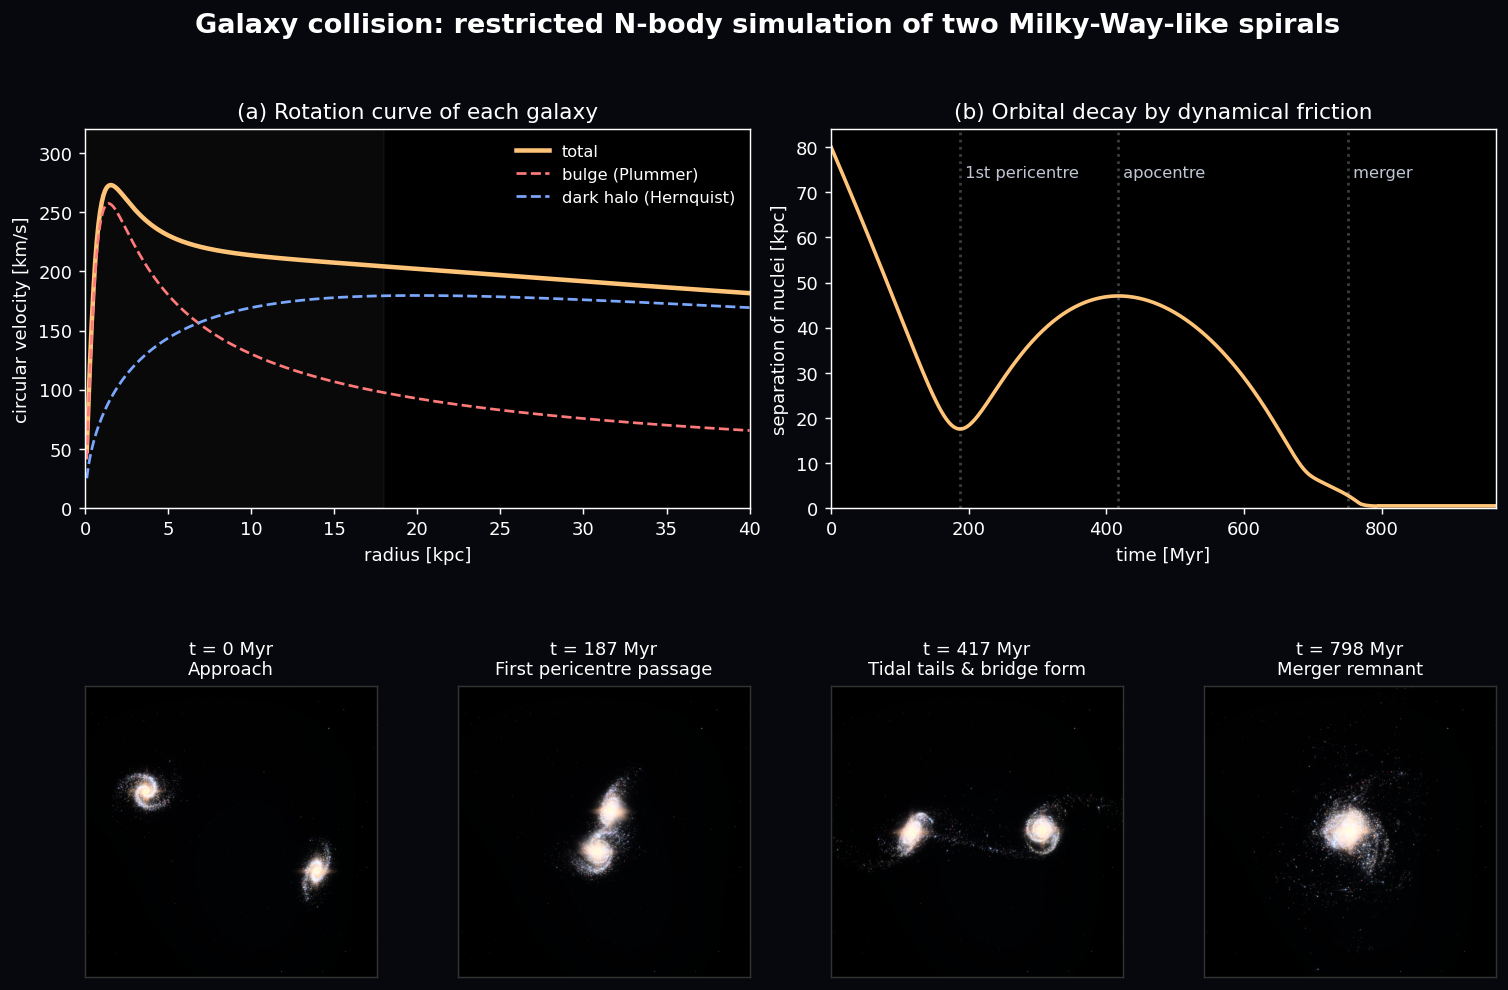

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started. If your browser asks, allow multiple downloads.


In [8]:
# 8. SHOW + AUTO-DOWNLOAD
display(Video(OUTPUT_VIDEO, embed=True, width=min(W, 720)))
display(IPImage(OUTPUT_PLOT))

if AUTO_DOWNLOAD:
    try:
        from google.colab import files
        files.download(OUTPUT_VIDEO)
        files.download(OUTPUT_PLOT)
        print("Download started. If your browser asks, allow multiple downloads.")
    except ImportError:
        print(f"Not running in Colab: files saved in {os.getcwd()}")
